In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
OUT_DIR = "."
random.seed(222)

import os
os.makedirs("data", exist_ok=True)
path = "data/export.csv"

if not os.path.exists(path):
    !pip install -q gdown
    import gdown
    gdown.download(id="h175LZByHn8MgAcZWswJLw40eq6nQ9YkGY", output=path)




In [ ]:
df = pd.read_csv(path, low_memory=False)
df = df.sample(n=100000)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
print(f"{len(df):,} rows x {df.shape[1]} columns")
df.head(3)

In [3]:
# Chicago's export format is "MM/DD/YYYY HH:MM:SS AM"; fall back to pandas inference otherwise.
for col in ["CRASH_DATE", "DATE_POLICE_NOTIFIED"]:
    parsed = pd.to_datetime(df[col], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    if parsed.isna().mean() > 0.5:
        parsed = pd.to_datetime(df[col], errors="coerce")
    df[col] = parsed

df["YEAR"] = df["CRASH_DATE"].dt.year
print("Date range:", df["CRASH_DATE"].min(), "->", df["CRASH_DATE"].max())
print("Unparseable CRASH_DATE:", df["CRASH_DATE"].isna().sum())
print("Duplicate CRASH_RECORD_ID:", df["CRASH_RECORD_ID"].duplicated().sum())
df["YEAR"].value_counts().sort_index()

Date range: 2014-01-18 18:14:00 -> 2026-10-29 23:09:00
Unparseable CRASH_DATE: 0
Duplicate CRASH_RECORD_ID: 0


YEAR
2014        2
2015      855
2016     4035
2017     7477
2018    10668
2019    10665
2020     8271
2021     9874
2022     9768
2023     9982
2024    10203
2025     9780
2026     8420
Name: count, dtype: int64

In [4]:
PLACEHOLDERS = {"UNKNOWN", "UNABLE TO DETERMINE", "NOT APPLICABLE", "OTHER", "UNKNOWN ALIGNMENT"}

def missing_report(frame):
    rows = []
    for c in frame.columns:
        s = frame[c]
        nan = s.isna().mean()
        hidden = s.astype(str).str.upper().isin(PLACEHOLDERS).mean() if (s.dtype == object or pd.api.types.is_string_dtype(s)) else 0.0
        rows.append((c, nan, hidden, nan + hidden, s.nunique(dropna=True)))
    return (pd.DataFrame(rows, columns=["column", "pct_nan", "pct_placeholder", "pct_effectively_missing", "n_unique"])
              .sort_values("pct_effectively_missing", ascending=False)
              .reset_index(drop=True))

miss = missing_report(df)
display_cols = miss[miss["pct_effectively_missing"] > 0]
print(display_cols.to_string(float_format=lambda x: f"{x:.1%}"))

                           column  pct_nan  pct_placeholder  pct_effectively_missing  n_unique
0               WORKERS_PRESENT_I    99.9%             0.0%                    99.9%         2
1                       DOORING_I    99.7%             0.0%                    99.7%         2
2                  WORK_ZONE_TYPE    99.6%             0.1%                    99.7%         4
3                     WORK_ZONE_I    99.5%             0.0%                    99.5%         2
4                  PHOTOS_TAKEN_I    98.6%             0.0%                    98.6%         2
5              STATEMENTS_TAKEN_I    97.6%             0.0%                    97.6%         2
6              NOT_RIGHT_OF_WAY_I    95.6%             0.0%                    95.6%         2
7                CRASH_DATE_EST_I    92.9%             0.0%                    92.9%         2
8                        LANE_CNT    82.2%             0.0%                    82.2%        22
9          SEC_CONTRIBUTORY_CAUSE     0.0%        

In [5]:
checks = {}

# Coordinates: missing, zeros, or outside a generous Chicago bounding box
CHI_LAT, CHI_LON = (41.64, 42.03), (-87.95, -87.52)
lat, lon = df["LATITUDE"], df["LONGITUDE"]
checks["lat/lon missing"] = (lat.isna() | lon.isna()).mean()
checks["lat/lon == 0"] = ((lat == 0) | (lon == 0)).mean()
in_box = lat.between(*CHI_LAT) & lon.between(*CHI_LON)
checks["lat/lon outside Chicago bbox (non-missing)"] = ((~in_box) & lat.notna() & (lat != 0)).mean()

# Speed limits that are not multiples of 5 (likely typos) or implausible
spd = df["POSTED_SPEED_LIMIT"]
checks["speed limit not multiple of 5"] = (spd % 5 != 0).mean()
checks["speed limit 0"] = (spd == 0).mean()
checks["speed limit > 70"] = (spd > 70).mean()

# Reporting lag
lag_h = (df["DATE_POLICE_NOTIFIED"] - df["CRASH_DATE"]).dt.total_seconds() / 3600
checks["police notified BEFORE crash"] = (lag_h < 0).mean()
checks["police notified > 7 days after"] = (lag_h > 24 * 7).mean()

# Estimated crash dates & injury fields
checks["crash date is estimated (CRASH_DATE_EST_I == Y)"] = (df["CRASH_DATE_EST_I"] == "Y").mean()
checks["INJURIES_TOTAL missing"] = df["INJURIES_TOTAL"].isna().mean()

# Times recorded exactly on the hour/midnight can indicate rounding / default values
checks["crash time exactly 00:00"] = ((df["CRASH_DATE"].dt.hour == 0) & (df["CRASH_DATE"].dt.minute == 0)).mean()
checks["crash minute == 0"] = (df["CRASH_DATE"].dt.minute == 0).mean()

pd.Series(checks, name="share_of_rows").map(lambda x: f"{x:.2%}").to_frame()

,share_of_rows
lat/lon missing,0.77%
lat/lon == 0,0.01%
lat/lon outside Chicago bbox (non-missing),0.00%
speed limit not multiple of 5,0.08%
speed limit 0,0.70%
speed limit > 70,0.01%
police notified BEFORE crash,0.00%
police notified > 7 days after,1.75%
crash date is estimated (CRASH_DATE_EST_I == Y),6.25%
INJURIES_TOTAL missing,0.20%


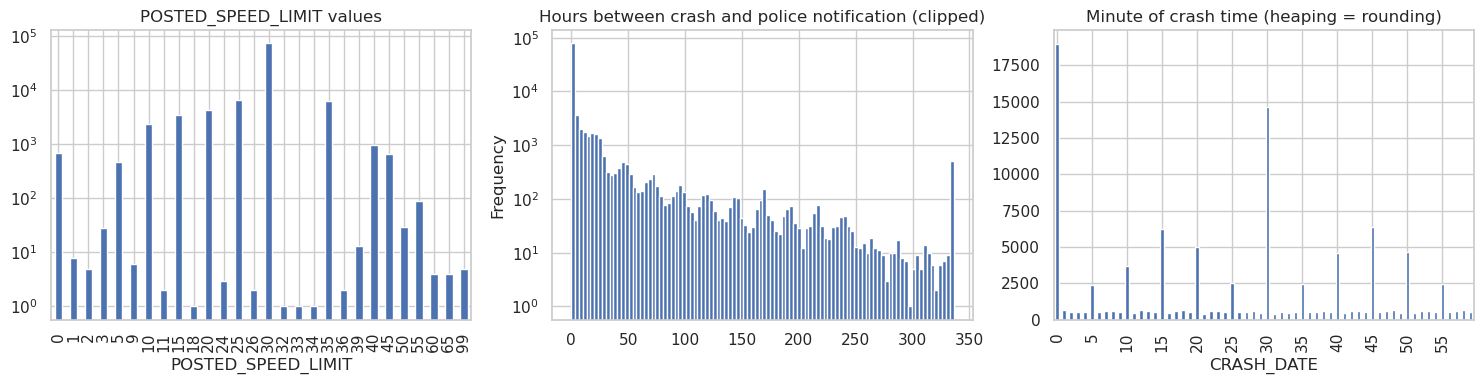

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
spd.value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("POSTED_SPEED_LIMIT values"); axes[0].set_yscale("log")
lag_h.clip(-24, 24 * 14).plot.hist(bins=100, ax=axes[1], color="#4C72B0")
axes[1].set_title("Hours between crash and police notification (clipped)"); axes[1].set_yscale("log")
df["CRASH_DATE"].dt.minute.value_counts().sort_index().plot.bar(ax=axes[2], color="#4C72B0")
axes[2].set_title("Minute of crash time (heaping = rounding)")
axes[2].set_xticks(range(0, 60, 5)); axes[2].set_xticklabels(range(0, 60, 5))
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/02_quality.png", dpi=150); plt.show()

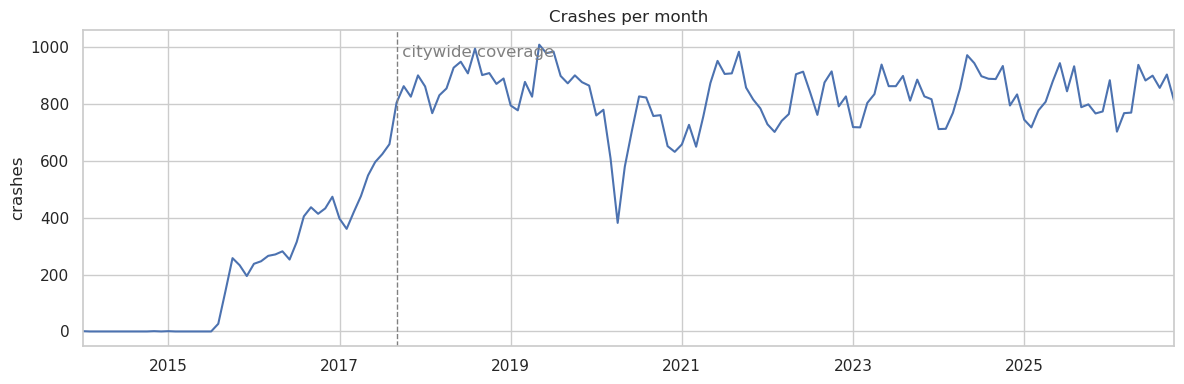

Analysis subset: 90,213 rows (90.2% of data)


In [7]:
monthly = df.set_index("CRASH_DATE").resample("MS").size()
ax = monthly.plot(figsize=(12, 4), color="#4C72B0")
ax.axvline(pd.Timestamp("2017-09-01"), color="grey", ls="--", lw=1)
ax.text(pd.Timestamp("2017-09-01"), ax.get_ylim()[1] * 0.95, " citywide coverage", va="top", color="grey")
ax.set_title("Crashes per month"); ax.set_ylabel("crashes"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_monthly.png", dpi=150); plt.show()

# Working subset for the rest of the analysis: full-coverage period, complete months only
START = pd.Timestamp("2017-09-01")
last_full_month = df["CRASH_DATE"].max().to_period("M").to_timestamp()
d = df[(df["CRASH_DATE"] >= START) & (df["CRASH_DATE"] < last_full_month)].copy()
print(f"Analysis subset: {len(d):,} rows ({len(d)/len(df):.1%} of data)")

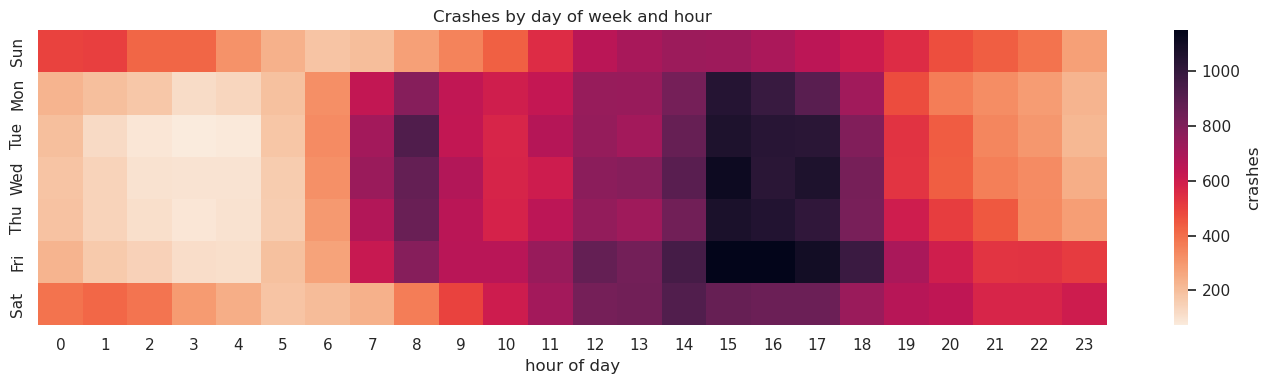

In [8]:
DOW = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
pivot = (d.pivot_table(index="CRASH_DAY_OF_WEEK", columns="CRASH_HOUR",
                       values="CRASH_RECORD_ID", aggfunc="count")
           .rename(index=DOW))
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(pivot, cmap="rocket_r", ax=ax, cbar_kws={"label": "crashes"})
ax.set_title("Crashes by day of week and hour"); ax.set_xlabel("hour of day"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/04_dow_hour.png", dpi=150); plt.show()

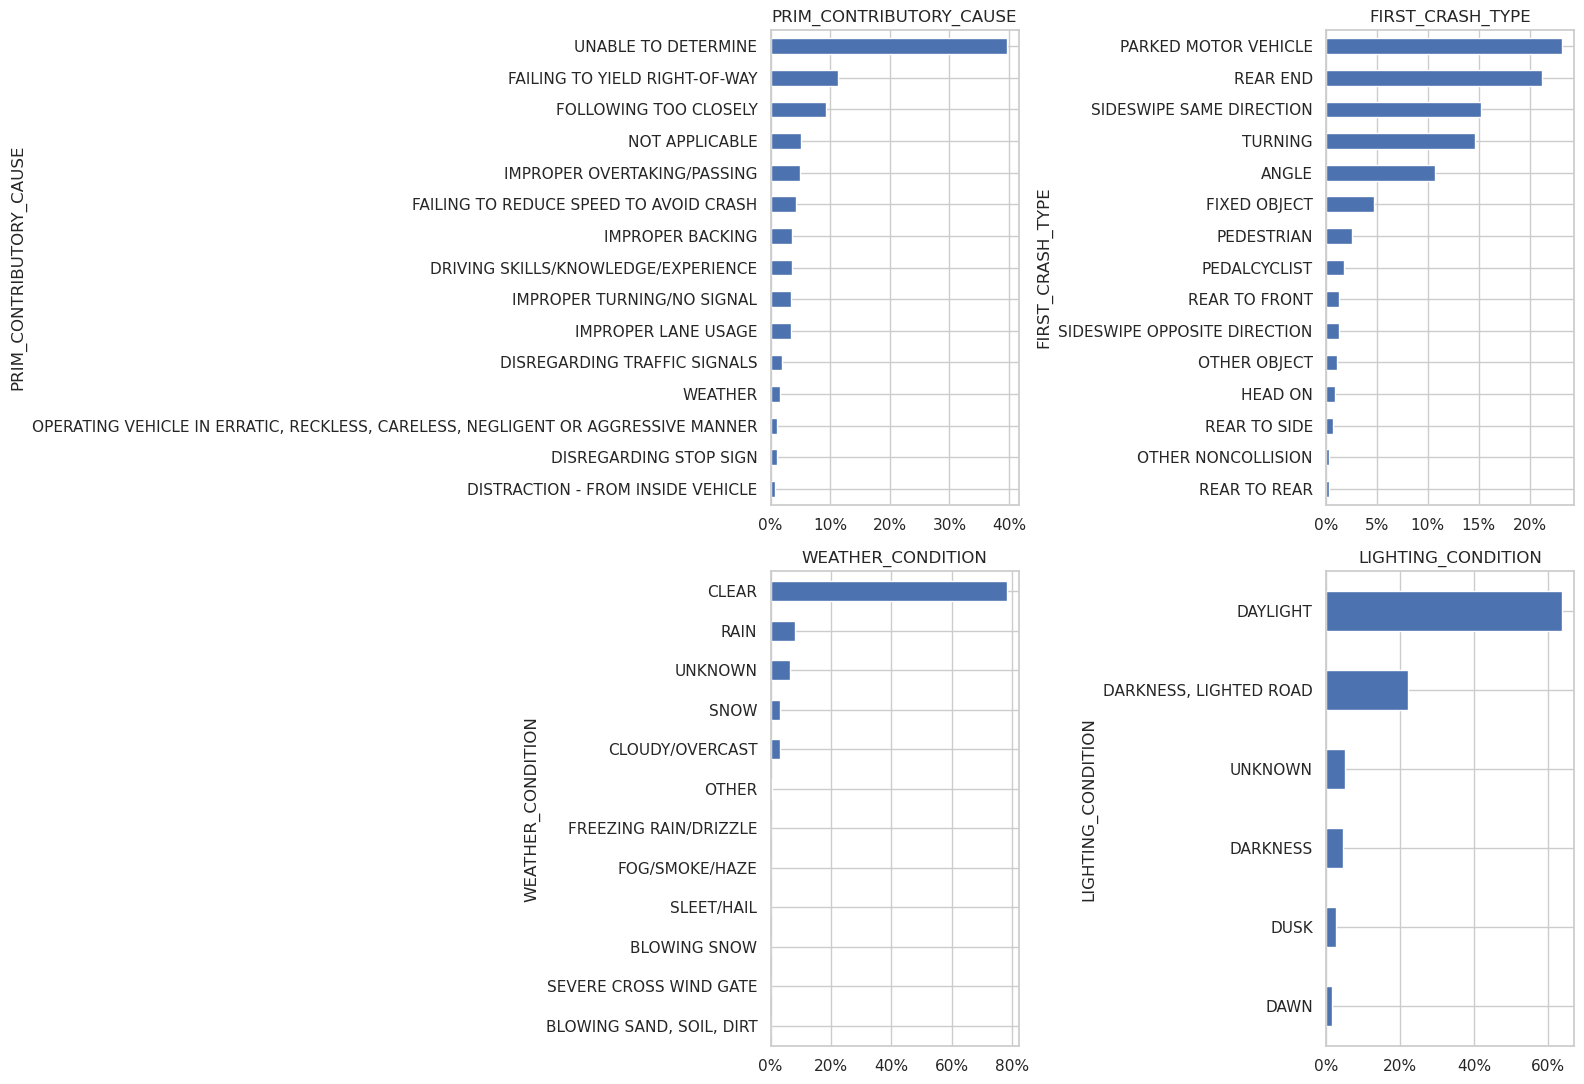

In [9]:
def top_counts(col, n=15, frame=d):
    return frame[col].value_counts(normalize=True).head(n)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, col in zip(axes.flat, ["PRIM_CONTRIBUTORY_CAUSE", "FIRST_CRASH_TYPE", "WEATHER_CONDITION", "LIGHTING_CONDITION"]):
    top_counts(col).sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set_title(col); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_categories.png", dpi=150); plt.show()

In [10]:
d["ANY_INJURY"] = d["INJURIES_TOTAL"].fillna(0) > 0
d["KSI"] = (d["INJURIES_FATAL"].fillna(0) + d["INJURIES_INCAPACITATING"].fillna(0)) > 0
print(d["MOST_SEVERE_INJURY"].value_counts(normalize=True).map("{:.2%}".format))
print(f"\nAny injury: {d['ANY_INJURY'].mean():.2%} | KSI: {d['KSI'].mean():.3%} | "
      f"fatal crashes: {(d['INJURIES_FATAL'] > 0).sum():,}")

def rate_table(col, min_n=500):
    g = d.groupby(col).agg(n=("CRASH_RECORD_ID", "size"), injury_rate=("ANY_INJURY", "mean"), ksi_rate=("KSI", "mean"))
    return g[g["n"] >= min_n].sort_values("ksi_rate", ascending=False)

for col in ["FIRST_CRASH_TYPE", "LIGHTING_CONDITION", "POSTED_SPEED_LIMIT", "PRIM_CONTRIBUTORY_CAUSE"]:
    print(f"\n=== {col} ===")
    print(rate_table(col).head(12).to_string(formatters={"injury_rate": "{:.1%}".format, "ksi_rate": "{:.2%}".format}))

MOST_SEVERE_INJURY
NO INDICATION OF INJURY     84.70%
NONINCAPACITATING INJURY     8.51%
REPORTED, NOT EVIDENT        5.05%
INCAPACITATING INJURY        1.64%
FATAL                        0.11%
Name: proportion, dtype: object

Any injury: 15.27% | KSI: 1.748% | fatal crashes: 103

=== FIRST_CRASH_TYPE ===
                                  n injury_rate ksi_rate
FIRST_CRASH_TYPE                                        
PEDESTRIAN                     2309       88.0%   15.72%
PEDALCYCLIST                   1595       72.2%    8.71%
HEAD ON                         770       35.3%    5.97%
FIXED OBJECT                   4268       18.0%    3.54%
ANGLE                          9685       25.2%    2.62%
OTHER OBJECT                    976       14.9%    2.36%
TURNING                       13185       17.7%    1.75%
SIDESWIPE OPPOSITE DIRECTION   1133       12.2%    1.68%
REAR END                      19165       14.3%    0.85%
REAR TO SIDE                    651        5.8%    0.77%
SIDESWIPE

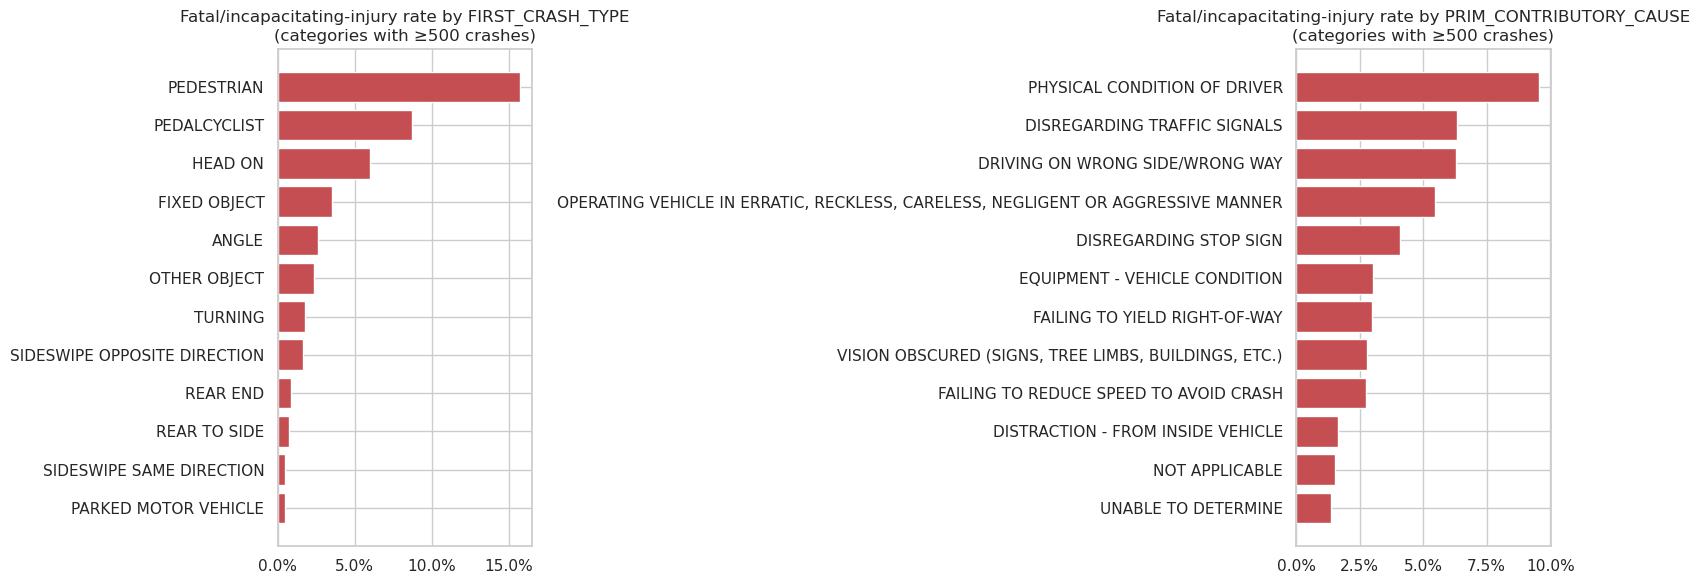

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col in zip(axes, ["FIRST_CRASH_TYPE", "PRIM_CONTRIBUTORY_CAUSE"]):
    t = rate_table(col).head(12).sort_values("ksi_rate")
    ax.barh(t.index, t["ksi_rate"], color="#C44E52")
    ax.set_title(f"Fatal/incapacitating-injury rate by {col}\n(categories with ≥500 crashes)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/06_severity.png", dpi=150); plt.show()

Mappable crashes: 89,484 (99.2% of analysis subset)


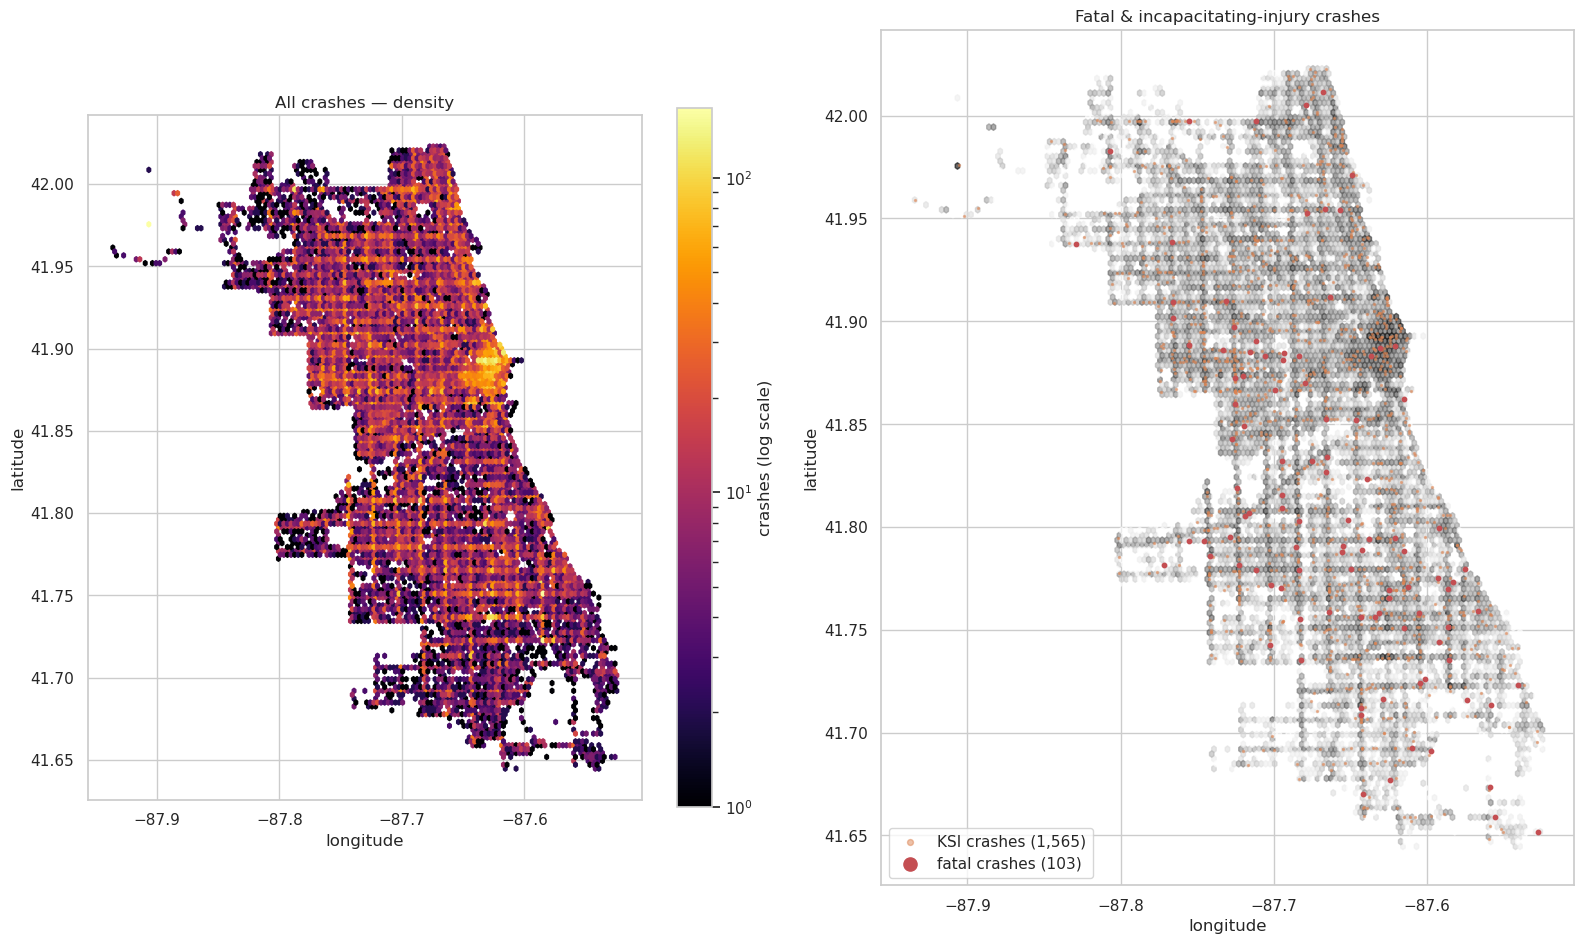

In [12]:
geo = d[d["LATITUDE"].between(*CHI_LAT) & d["LONGITUDE"].between(*CHI_LON)].copy()
print(f"Mappable crashes: {len(geo):,} ({len(geo)/len(d):.1%} of analysis subset)")

# Correct aspect ratio for Chicago's latitude
aspect = 1 / np.cos(np.deg2rad(41.85))

fig, axes = plt.subplots(1, 2, figsize=(16, 12))
hb = axes[0].hexbin(geo["LONGITUDE"], geo["LATITUDE"], gridsize=140, bins="log", cmap="inferno", mincnt=1)
fig.colorbar(hb, ax=axes[0], shrink=0.6, label="crashes (log scale)")
axes[0].set_title("All crashes — density")

axes[1].hexbin(geo["LONGITUDE"], geo["LATITUDE"], gridsize=140, bins="log", cmap="Greys", mincnt=1, alpha=0.6)
ksi = geo[geo["KSI"]]
fatal = geo[geo["INJURIES_FATAL"] > 0]
axes[1].scatter(ksi["LONGITUDE"], ksi["LATITUDE"], s=2, c="#DD8452", alpha=0.5, label=f"KSI crashes ({len(ksi):,})")
axes[1].scatter(fatal["LONGITUDE"], fatal["LATITUDE"], s=10, c="#C44E52", label=f"fatal crashes ({len(fatal):,})")
axes[1].legend(loc="lower left", markerscale=3)
axes[1].set_title("Fatal & incapacitating-injury crashes")
for ax in axes:
    ax.set_aspect(aspect); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/07_map_static.png", dpi=150); plt.show()

In [13]:
geo["BLOCK"] = (geo["STREET_NO"].astype(str) + " " + geo["STREET_DIRECTION"].fillna("") + " " + geo["STREET_NAME"].fillna("")).str.strip()
hot = (geo.groupby("BLOCK").agg(crashes=("CRASH_RECORD_ID", "size"), injuries=("INJURIES_TOTAL", "sum"),
                                ksi=("KSI", "sum"), lat=("LATITUDE", "median"), lon=("LONGITUDE", "median"))
          .sort_values("crashes", ascending=False))
print(hot.head(20).to_string())
print("\nTop streets by crash count:")
print(geo["STREET_NAME"].value_counts().head(15).to_string())

                          crashes  injuries  ksi        lat        lon
BLOCK                                                                 
10000 W OHARE ST              166      26.0    1  41.976201 -87.905309
5700 S LAKE SHORE DR           65      20.0    2  41.791420 -87.580148
7900 S STONY ISLAND AVE        62      26.0    3  41.751461 -87.585972
9500 S STONY ISLAND AVE        46      13.0    0  41.722257 -87.585276
1000 N LAKE SHORE DR SB        43      11.0    0  41.900959 -87.619928
7601 S CICERO AVE              35       2.0    1  41.754660 -87.741385
200 W 87TH ST                  34       5.0    0  41.736262 -87.629065
1000 N LAKE SHORE DR NB        31       9.0    1  41.900959 -87.619928
5700 S CICERO AVE              29       5.0    0  41.789329 -87.741646
9900 S HALSTED ST              28       1.0    0  41.714119 -87.643145
5500 S WESTERN AVE             27       6.0    0  41.793371 -87.684175
8700 S COTTAGE GROVE AVE       26       4.0    0  41.736602 -87.604968
600 E 

In [15]:
# Interactive map — runs if folium is installed (pip install folium)
try:
    import folium
    from folium.plugins import HeatMap, MarkerCluster

    m = folium.Map(location=[41.8781, -87.6298], zoom_start=11, tiles=None)
    sample = geo.sample(min(len(geo), 150_000), random_state=0)
    folium.TileLayer("OpenStreetMap", name="Streets").add_to(m)
    folium.TileLayer("CartoDB positron", name="Light").add_to(m)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Esri", name="Satellite").add_to(m)

    HeatMap(sample[["LATITUDE", "LONGITUDE"]].values.tolist(),
            radius=7, blur=9, min_opacity=0.2, max_zoom=13,   # fades as you zoom in
            name="All crashes (heat)").add_to(m)

    fatal_layer = folium.FeatureGroup(name="Fatal crashes", show=True)
    for _, r in fatal.iterrows():
        folium.CircleMarker(
            [r["LATITUDE"], r["LONGITUDE"]], radius=4, color="#C44E52", fill=True, fill_opacity=0.9,
            popup=folium.Popup(f"{r['CRASH_DATE']:%Y-%m-%d %H:%M}<br>{r['FIRST_CRASH_TYPE']}<br>"
                               f"Cause: {r['PRIM_CONTRIBUTORY_CAUSE']}<br>Fatalities: {int(r['INJURIES_FATAL'])}",
                               max_width=280)).add_to(fatal_layer)
    fatal_layer.add_to(m)
    folium.LayerControl().add_to(m)
    m.save(f"{OUT_DIR}/crash_map.html")
    print("Saved interactive map to crash_map.html")
    try:
        from IPython.display import display
        display(m)
    except ImportError:
        pass
except ImportError:
    print("folium not installed — run `pip install folium` for the interactive map.")

Saved interactive map to crash_map.html
